# Session 5 -

 Tuning a model for our usage ( Freezing , lower lr, add your last layer or other layer if you want to a pretrained one) - gradient vanish and solve the problem - handling dense layers which cause high costs on CNNs -avg maxpool - handling pics with 3 channels rgb (use depth wise point wise (kernel 1*1)) etc.

Fine-tuning means taking a neural network that was already trained on a large, general dataset (like ImageNet) and adapting its learned parameters to solve your specific task using your own dataset. Instead of training millions of parameters from scratch, you reuse the general visual features (edges, textures, shapes) already present in the base model and fine-tune the parameters to fit your custom inputs and target outputs.

---

## Core Concepts Summary

### 1. Fine-Tuning Mechanics

* **Freezing Layers:** Early layers capture low-level, universal features. By setting their weights as non-trainable (`requires_grad = False`), you preserve these representations, save computation time, and prevent overfitting on smaller custom datasets.
* **Replacing the Classification Head:** The original final fully connected layer is configured for the base model's task (e.g., 1,000 classes for ImageNet). You replace this output layer with a new layer matching your target problem's class count.
* **Lower Learning Rate ($\eta$):** When unfreezing and adjusting the model's base layers, you use a much smaller learning rate (e.g., $10^{-4}$ or $10^{-5}$) so gradient updates tweak the existing weights gently without destroying ("catastrophically forgetting") the pretrained features.

### 2. Vanishing Gradient Problem & Solutions

* **The Problem:** In deep networks during backpropagation, gradients calculated via the chain rule are repeatedly multiplied layer by layer. When using activation functions like Sigmoid or Tanh (whose derivatives are $\le 0.25$), these gradients shrink exponentially as they flow backward toward the input layers, causing early layers to stop updating.
* **Solutions:**
* **ReLU Activations:** $\text{ReLU}(x) = \max(0, x)$ maintains a constant derivative of $1$ for positive inputs, avoiding gradient decay.
* **Residual Connections (Skip Connections):** Pass gradients directly backward through identity paths without attenuation (as in ResNet).
* **Batch Normalization:** Keeps intermediate activations in stable ranges, preventing signals from decaying into flat activation regions.
* **He / Xavier Initialization:** Initializes weights at proper scales so signal magnitudes don't collapse during early passes.



### 3. Replacing Heavy Dense Layers in CNNs

* **The Bottleneck:** Traditional CNNs (like VGG) flattened high-dimensional spatial feature maps into huge Fully Connected (FC) dense layers, which often accounted for over 80% of total network parameters.
* **Global Average Pooling (GAP):** Modern CNN architectures replace heavy dense layers by reducing each spatial feature map ($H \times W$) to a single scalar value through spatial averaging ($1 \times 1 \times C$). This converts feature maps directly into class logits or vectors, reducing parameter counts and preventing severe overfitting.

### 4. Efficient Channel Processing: Depthwise Separable Convolutions

Standard 2D convolutions process spatial dimensions ($K \times K$) and cross-channel interactions simultaneously, requiring large computational resources ($K_w \times K_h \times C_{\text{in}} \times C_{\text{out}}$ ops per spatial location). **Depthwise Separable Convolutions** (used in MobileNet) split this into two distinct steps:

* **Depthwise Convolution:** Applies a spatial $K \times K$ kernel independently to **each input channel** without mixing channels.
* **Pointwise Convolution ($1 \times 1$ Kernel):** Applies a $1 \times 1$ kernel across all depth channels at each pixel to mix spatial outputs across channels and adjust feature dimensions ($C_{\text{out}}$).
* **Impact:** This factorized split cuts computational cost and total parameter count by roughly $80\text{--}90\%$ compared to standard convolutions with minimal accuracy loss.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from flax.experimental.nnx.docs.why import layer
from tensorflow.python.keras.layers import GlobalAvgPool2D

## Class material

In [5]:
# using a pretrained model
from tensorflow.keras.applications import ResNet50
model = ResNet50(weights='imagenet', include_top=False)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [8]:
model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, None,      │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, None,      │      9,472 │ conv1_pad[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, None,      │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, None,      │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, None,      │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, None,      │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, None,      │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, None,      │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, None,      │          0 │ conv2_block1_1_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, None,      │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, None,      │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, None,      │          0 │ conv2_block1_2_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, None,      │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, None,      │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, None,      │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, None,      │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [23]:
len(model.layers)

175

In [27]:
layer = model.get_layer(name='conv5_block2_2_conv')
layer.weights

[<Variable path=conv5_block2_2_conv/kernel, shape=(3, 3, 512, 512), dtype=float32, value=[[[[ 9.20530595e-03  7.03070732e-03 -1.02405446e-02 ... -9.61417740e-04
     -9.71355196e-03 -7.15076085e-03]
    [-4.85496270e-03 -1.00081405e-02  3.84005420e-02 ...  1.86559244e-03
     -5.95903257e-04 -1.79451145e-02]
    [-2.87569407e-03 -3.54379695e-03  3.64305731e-03 ... -5.77661954e-03
     -3.90686886e-03  9.38555133e-03]
    ...
    [ 2.47509917e-03  5.86470775e-03 -1.56231979e-02 ...  9.91540146e-04
     -1.18864169e-02  6.88561192e-03]
    [ 1.58446981e-03 -4.45518643e-03  7.75002036e-03 ...  7.72014773e-03
      1.44257853e-02  7.77397014e-04]
    [ 1.11135459e-02  5.83167002e-03 -3.93972732e-03 ... -1.22326929e-02
     -7.52686430e-03  7.17201387e-04]]
 
   [[ 5.72288828e-03  1.20709650e-02 -8.54832027e-03 ... -1.17996735e-02
     -8.20476841e-03 -1.05633996e-02]
    [-1.13401599e-02 -1.16994260e-02  2.45875493e-02 ...  1.26870722e-02
      4.05099476e-03 -1.26009658e-02]
    [-1.92184

In [30]:
layer.output

<KerasTensor shape=(None, None, None, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_158>

In [31]:
layer.input

<KerasTensor shape=(None, None, None, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_157>

In [34]:
from tensorflow.keras.layers import Dense, Dropout, Flatten


# how to tune a model :

# suppose you remove last layer and replace it with a 5 classes output layer

#model + Dense(5, activation="softmax")
#layer[0:171].trainable = False
#layer[171:].trainable = True



### Skip path - FUNCTIONAL api

You are partially right on the structural concept, but let's clarify the terminology and how this works in practice.

---

### Clarifying the Mechanics

1. **What is the Functional API?**
* **Yes, you are right** that building networks where inputs bypass intermediate steps, branch out, or concatenate requires the **Functional API** (in Keras/TensorFlow) or custom `forward()` graphs (in PyTorch).
* The basic `Sequential` model only allows a single linear chain of layers ($A \to B \to C$). The Functional API allows multi-input, multi-output, or non-linear directed acyclic graphs (DAGs).


2. **Does passing raw inputs to later layers fix learning speed?**
* Connecting the original input directly to deeper layers (or combining tabular/metadata inputs alongside image features) is often called a **Skip-Connection** or a **Wide & Deep Network**.
* However, feeding raw high-dimensional pixels directly into deep layers does **not** directly fix gradient vanishing or slow learning across deep networks. The features in deep layers are high-level abstractions (semantic shapes), while raw input features are low-level (raw pixel values), so concatenation creates a dimension and feature-type mismatch that intermediate layers still have to transform.



---

### What Actually Solves the "Slower Learning in Deeper Layers" Problem?

#### 1. Residual Connections (ResNets)

Instead of feeding the raw input image all the way to the end, **ResNets** pass the output of an earlier layer directly to a later layer by adding them together:


$$\text{Output} = F(x) + x$$


Because gradients flow back through the $+ x$ addition operation unchanged (gradient of addition is $1$), backpropagation bypasses intermediate transformations without decaying.

#### 2. Dense Connections (DenseNets)

**DenseNet** explicitly uses **concatenation** (via the Functional API). Every layer receives the feature maps of *all preceding layers* concatenated together:


$$\text{Layer}_l = \text{Concat}(\text{Layer}_1, \text{Layer}_2, \dots, \text{Layer}_{l-1})$$


This ensures direct gradient flow and feature reuse throughout the entire architecture.

#### 3. Auxiliary Classifiers (Inception / GoogLeNet)

In very deep networks, intermediate "side-branch" loss functions (auxiliary classifiers) are attached to middle layers during training. These inject gradients directly into middle layers to prevent early/middle parameters from updating too slowly.

---

### Example: Keras Functional API Concatenation

If you want to feed the raw input directly alongside processed features into the final dense layers, you build it using `Concatenate()`:

```python
import tensorflow as tf
from tensorflow.keras import layers, Model

# 1. Input Layer
input_img = layers.Input(shape=(228, 228, 3), name="raw_input")

# 2. Main Feature Extraction Branch
x = layers.Conv2D(32, (3, 3), activation="relu")(input_img)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.GlobalAveragePooling2D()(x)  # Shape: (Batch, 32)

# 3. Flatten raw input to concatenate
flat_input = layers.Flatten()(input_img)  # Shape: (Batch, 228*228*3)

# 4. Concatenate raw input + extracted features
combined = layers.Concatenate()([x, flat_input])

# 5. Output Layer
output = layers.Dense(10, activation="softmax")(combined)

# Build Model via Functional API
model = Model(inputs=input_img, outputs=output)

```

In [44]:
### Functional api in last layer
import tensorflow as tf
from tensorflow.keras import layers , Model
input_img = layers.Input(shape=(224,224,3),name = 'raw input')

# feature extraction branches
x = layers.Conv2D(32, (3, 3), activation='relu')(input_img)
x = layers.MaxPooling2D()(x)
x = layers.GlobalAvgPool2D()(x)

#flatten
flat_input = layers.Flatten()(input_img)

# concatenate
combined = layers.Concatenate()([x, flat_input])

# output
output = layers.Dense(10, activation='softmax')(combined)

# Build Model via Functional API
model = Model(inputs=input_img, outputs=output)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 222, 222,  │        896 │ raw input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 111, 111,  │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ max_pooling2d_4[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 150528)    │          0 │ raw input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 150560)    │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 10)        │  1,505,610 │ concatenate_3[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,506,506 (5.75 MB)

 Trainable params: 1,506,506 (5.75 MB)

 Non-trainable params: 0 (0.00 B)

Yes, you can absolutely use skip-connections in middle layers—and that is actually where they are most effective and standard in deep learning.

Connecting the raw input directly to the **output layer** (as shown in the code) versus passing intermediate feature maps between **middle layers** serves two very different architectural purposes:

---

## 1. Direct Input-to-Output Connections (Wide & Deep Architecture)

When you connect raw input directly to the final classification layer alongside processed deep features, you are building a **Wide & Deep** pattern.

### Why it is useful:

* **Combining "Memorization" and "Generalization":**
* **The Deep Path (CNN branch):** Learns abstract, generalized visual representations (shapes, textures, high-level features).
* **The Wide Path (Raw/Flattened input branch):** Memorizes specific, raw pixel-level correlations or raw input signals directly tied to the target label.


* **Multimodal or Tabular + Image Hybrid Models:** This pattern is very popular when combining different types of data—for instance, passing an image through CNN layers while feeding metadata (like price, age, or category numerical features) directly into the final classification layer.

### The Drawback of raw pixel flattened input to output:

Flattening a $228 \times 228 \times 3$ raw image produces $155,952$ features. Connecting this directly to a Dense layer creates a massive parameter explosion ($155,952 \times 10 \approx 1.56 \text{ million}$ weights in that layer alone), defeating the parameter efficiency of CNNs and risking heavy overfitting.

---

## 2. Skip-Connections in Middle Layers (ResNet & DenseNet Style)

In standard deep learning architectures, skip-connections (concatenation or addition) are almost always added **between middle layers**, rather than from raw input to output.

```
       ┌───────────────────── (Skip Path) ────────────────────┐
       │                                                      ▼
Input ──► [Conv Layer 1] ──► [Conv Layer 2] ──► [Conv Layer 3] ──► [Concatenate / Add] ──► Output

```

### Why doing this in middle layers is much better:

1. **Prevents Vanishing Gradients:**
During backpropagation, the gradient flows directly through the skip path without being repeatedly multiplied by small weight matrices across deep layers. This keeps gradients healthy across dozens or hundreds of layers.
2. **Multi-Scale Feature Reuse:**
Early and middle layers extract low-level spatial details (edges, colors, corners), while later layers extract high-level semantic concepts (faces, objects). Concatenating middle layers allows the network to make decisions using **both coarse and fine visual details** simultaneously.
3. **Prevents Feature Degradation:**
As data passes through layer after layer of non-linear activations (like ReLU) and pooling operations, original spatial details can get lost or washed out. Middle skip-connections re-inject pristine representations from earlier stages.

---

## Middle Layer Concatenation Example (Functional API)

Here is how you write a middle-layer skip connection using `Concatenate` in Keras:

```python
import tensorflow as tf
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(228, 228, 3))

# Block 1: Low-level features
x1 = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)

# Block 2: Deeper features
x2 = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x1)

# Middle Layer Skip Connection: Concatenate Block 1 output with Block 2 output
x_combined = layers.Concatenate()([x1, x2])  # Combines early & deep features

# Block 3: Further processing
x3 = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x_combined)

# Classification Head
gap = layers.GlobalAveragePooling2D()(x3)
outputs = layers.Dense(10, activation="softmax")(gap)

model = Model(inputs=inputs, outputs=outputs)

```

In [46]:
# Middle Layer Concatenation Example (Functional API)
import tensorflow as tf
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(228, 228, 3))

# Block 1: Low-level features
x1 = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)

# Block 2: Deeper features
x2 = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x1)

# Middle Layer Skip Connection: Concatenate Block 1 output with Block 2 output
x_combined = layers.Concatenate()([x1, x2])  # Combines early & deep features

# Block 3: Further processing
x3 = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x_combined)

# Classification Head
gap = layers.GlobalAveragePooling2D()(x3)
outputs = layers.Dense(10, activation="softmax")(gap)

model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 228, 228,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 228, 228,  │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 228, 228,  │      9,248 │ conv2d_8[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 228, 228,  │          0 │ conv2d_8[0][0],   │
│ (Concatenate)       │ 64)               │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 228, 228,  │     36,928 │ concatenate_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv2d_10[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 10)        │        650 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 47,722 (186.41 KB)

 Trainable params: 47,722 (186.41 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
## Practice : code the below one into a correct form

model = models.Model()

input_layer = layers.Input(shape=(784,))
dense_1 = layers.Dense(64, activation='relu')
dense_2 = layers.Dense(32, activation='relu')
dense_3 = layers.Dense(16, activation='relu')
output_layer = layers.Dense(10, activation='softmax')

out_1 = input_layer(X)
out_1 = out_1 + 1
out_2 = dense_1(out_1)
out_3 = dense_2(out_2)
out_4 = dense_2([out_3, X])
output = dense_3(out_4)

model(input_layer, output_layer)

In [52]:
input = layers.Input(shape=(784,))
dense_1 = layers.Dense(64, activation='relu')
dense_2 = layers.Dense(32, activation='relu')
dense_3 = layers.Dense(16, activation='relu')
output_layer = layers.Dense(10, activation='softmax')

# pass
out_1 = dense_1(input)
out_2 = dense_2(out_1)

combined = layers.Concatenate()([out_2, input])

out_3 = dense_3(combined)
output = output_layer(out_3)

model = Model(inputs=input, outputs=output)

model.summary()



Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 64)        │     50,240 │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 32)        │      2,080 │ dense_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 816)       │          0 │ dense_19[0][0],   │
│ (Concatenate)       │                   │            │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 16)        │     13,072 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 10)        │        170 │ dense_20[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 65,562 (256.10 KB)

 Trainable params: 65,562 (256.10 KB)

 Non-trainable params: 0 (0.00 B)

### Globalavgpool - dilation rate


In [7]:
from tensorflow.keras import models, layers
model = models.Sequential([
    layers.Input(shape=(32,32,3)),

    layers.Conv2D(filters= 32, kernel_size= (3, 3), activation='relu', strides=(1,1), padding="same", dilation_rate=2),
    layers.Conv2D(32, (3, 3), activation='relu',padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu',padding="same"),
    layers.Conv2D(64, (3, 3), activation='relu',padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu',padding="same"),
    layers.Conv2D(128, (3, 3), activation='relu',padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # layers.Flatten(),
    # layers.Dense(1024, activation='relu'),  # 2,098,176  ==> 4,128
    #
    layers.GlobalAvgPool2D(),
    layers.Dense(5, activation='softmax'),
])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 287,653 (1.10 MB)

 Trainable params: 287,653 (1.10 MB)

 Non-trainable params: 0 (0.00 B)

## Cifra Problem enhanced one - new concept : SeparableConv2D

`SeparableConv2D` in `tensorflow.keras.layers` implements a **Depthwise Separable Convolution**.

Its main purpose is to dramatically **reduce the number of parameters and computation cost** compared to a standard `Conv2D` layer, while learning nearly identical visual representations.

---

## 1. The Core Idea: Splitting 2D Convolution into 2 Steps

A standard `Conv2D` layer performs spatial filtering (across height and width) and channel mixing (across depth) **simultaneously** in a single operation.

`SeparableConv2D` factorizes this single heavy operation into two smaller, consecutive steps:

1. **Step 1: Depthwise Convolution (Spatial Filtering)**
Applies a single $K \times K$ spatial kernel to **each input channel individually**. Channels are kept separate and are not mixed here.
2. **Step 2: Pointwise Convolution (Channel Mixing)**
Applies a $1 \times 1$ convolution across all depth channels to mix the spatial outputs together and project them to the desired number of output channels (`filters`).

---

## 2. Visual Comparison

---

## 3. Parameter Comparison (The Efficiency Gain)

To see why `SeparableConv2D` is so popular in lightweight models (like MobileNet and Xception), let's compare the math for processing a tensor:

* **Input:** $100 \times 100$ image with $64$ channels (`C_in = 64`)
* **Output:** $64$ output filters (`C_out = 64`)
* **Kernel Size:** $3 \times 3$ (`K = 3`)

### Standard `Conv2D`:

Every filter looks at all input channels simultaneously.


$$\text{Parameters} = K \times K \times C_{\text{in}} \times C_{\text{out}}$$

$$\text{Parameters} = 3 \times 3 \times 64 \times 64 = \mathbf{36,864 \text{ weights}}$$

### `SeparableConv2D`:

1. **Depthwise Step:** $3 \times 3 \times 64 = 576$ weights
2. **Pointwise Step ($1 \times 1$):** $1 \times 1 \times 64 \times 64 = 4,096$ weights

$$\text{Total Parameters} = 576 + 4,096 = \mathbf{4,672 \text{ weights}}$$



> **Result:** `SeparableConv2D` uses **~87% fewer parameters and computations** for this layer! In general, it reduces computational complexity by approximately a factor of $\frac{1}{N_{\text{filters}}} + \frac{1}{K^2}$.

---

## 4. Usage in `tf.keras`

The syntax for `SeparableConv2D` is practically identical to `Conv2D`:

```python
import tensorflow as tf
from tensorflow.keras import layers, models

# Standard Heavy Convolution
standard_conv = layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu')

# Lightweight Depthwise Separable Convolution
separable_conv = layers.SeparableConv2D(filters=64, kernel_size=(3, 3), activation='relu')

```

---

## Summary Checklist

| Feature | `Conv2D` | `SeparableConv2D` |
| --- | --- | --- |
| **Operation** | Joint spatial + depth convolution in 1 pass | 2 separate steps (Depthwise $K \times K$ + Pointwise $1 \times 1$) |
| **Parameter Count** | High | **Low (80–90% fewer params)** |
| **Speed & Efficiency** | Slower, heavier memory footprint | **Faster, mobile/edge friendly** |
| **Primary Use Cases** | Large desktop/server models (VGG, ResNet) | Efficient architectures (MobileNet, Xception) |

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import cifar10

from sklearn.model_selection import train_test_split

In [11]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [12]:
X_test,X_val, y_test, y_val = train_test_split(X_test, y_test, test_size = 0.2,stratify = y_test)

In [13]:
print(X_train.shape,X_test.shape,X_val.shape,y_train.shape,y_test.shape,y_val.shape)

(50000, 32, 32, 3) (8000, 32, 32, 3) (2000, 32, 32, 3) (50000, 1) (8000, 1) (2000, 1)


In [14]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0

In [17]:
model = models.Sequential([
    layers.Input(shape=(32,32,3)),
    layers.SeparableConv2D(32,(3,3),padding="same",activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.SeparableConv2D(64,(3,3),padding="same",activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.GlobalAvgPool2D(),
    layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_3              │ (None, 32, 32, 32)     │           155 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_4              │ (None, 16, 16, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,205 (12.52 KB)

 Trainable params: 3,205 (12.52 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
from tensorflow.keras.callbacks import TensorBoard
from tensorflow.keras import callbacks
tensorboard = TensorBoard(log_dir='./logs', histogram_freq=0, write_graph=True, write_images=True)

In [21]:
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

In [23]:
history = model.fit(X_train,y_train, validation_data=(X_val,y_val), epochs=20, batch_size=32, callbacks=[tensorboard])

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.3873 - loss: 1.6673 - val_accuracy: 0.3935 - val_loss: 1.6648
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.4017 - loss: 1.6411 - val_accuracy: 0.4065 - val_loss: 1.6482
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4114 - loss: 1.6162 - val_accuracy: 0.4045 - val_loss: 1.6384
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4216 - loss: 1.5943 - val_accuracy: 0.4115 - val_loss: 1.5984
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4298 - loss: 1.5696 - val_accuracy: 0.4195 - val_loss: 1.5967
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4380 - loss: 1.5522 - val_accuracy: 0.4385 - val_loss: 1.5586
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4442 - loss: 1.5306 - val_accuracy: 0.4425 - val_loss: 1.5442
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4519 - loss: 1

In [24]:
history = history.history

In [25]:
model.evaluate(X_test,y_test)

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5126 - loss: 1.3432


[1.3432495594024658, 0.512624979019165]

In [26]:
y_pred = model.predict(X_test)

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [27]:
from sklearn.metrics import confusion_matrix,classification_report

In [28]:
y_pred=np.argmax(y_pred,axis=1)


<Axes: >

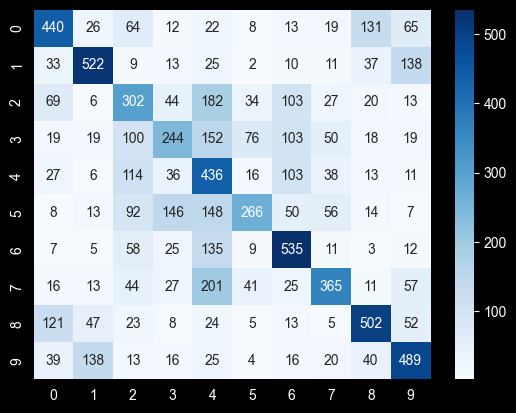

In [29]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt="g",cmap="Blues")

In [30]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.56      0.55      0.56       800
           1       0.66      0.65      0.65       800
           2       0.37      0.38      0.37       800
           3       0.43      0.30      0.36       800
           4       0.32      0.55      0.41       800
           5       0.58      0.33      0.42       800
           6       0.55      0.67      0.60       800
           7       0.61      0.46      0.52       800
           8       0.64      0.63      0.63       800
           9       0.57      0.61      0.59       800

    accuracy                           0.51      8000
   macro avg       0.53      0.51      0.51      8000
weighted avg       0.53      0.51      0.51      8000



In [31]:
np.where(y_test==8)

(array([   0,    1,    4,   23,   26,   41,   42,   49,   54,   65,   66,
          85,  117,  122,  134,  137,  150,  165,  171,  174,  175,  177,
         192,  203,  205,  208,  232,  247,  256,  258,  260,  266,  306,
         307,  311,  319,  330,  344,  348,  365,  385,  407,  411,  432,
         441,  513,  516,  525,  535,  538,  541,  570,  598,  603,  622,
         623,  653,  665,  667,  668,  685,  706,  713,  717,  733,  737,
         739,  751,  756,  765,  803,  804,  813,  814,  826,  837,  853,
         857,  883,  889,  901,  903,  909,  911,  920,  932,  933,  967,
         973,  989,  996,  997, 1036, 1046, 1050, 1055, 1064, 1068, 1070,
        1079, 1081, 1082, 1085, 1088, 1097, 1098, 1102, 1115, 1125, 1126,
        1136, 1157, 1166, 1173, 1185, 1203, 1222, 1228, 1233, 1242, 1268,
        1282, 1313, 1316, 1322, 1328, 1337, 1349, 1363, 1365, 1372, 1378,
        1379, 1381, 1384, 1392, 1401, 1405, 1409, 1410, 1425, 1432, 1455,
        1458, 1471, 1485, 1489, 1491, 

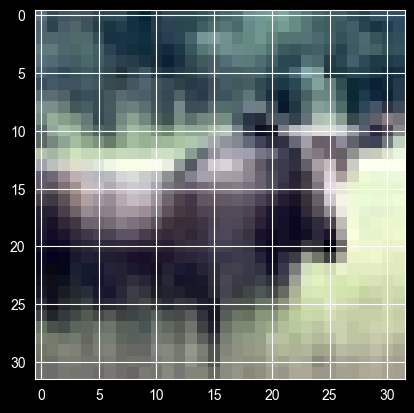

In [32]:
plt.imshow(X_test[22],cmap="Blues")